### Objective: To test external datasets from the protein gym. 

69 of the substitution datasets contain double mutants. I want to use these to test my code. And explore epistasis. 

In [ ]:
from pathlib import Path

import matplotlib.pylab as plt
import numpy as np
import pandas as pd
import seaborn as sns
from itables import show

from protein_epistasis.lattice.graph import (
    construct_child_to_parent_map,
    construct_index_to_mutations_map,
    construct_mutation_number_map,
    construct_mutations_to_index_map,
    find_parent_sequences,
)
from protein_epistasis.metrics.scores import (
    construct_child_parent_dataframe,
    construct_sequence_to_score_map,
)
from protein_epistasis.utils import ls

%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Load the metadata file 

In [53]:
base_path = Path().cwd().parent
data_path = base_path/ 'external_data'

print(ls(data_path))
metadata = pd.read_csv(data_path/'DMS_substitutions.csv')
metadata.head()

[PosixPath('/Users/christopherrivera/Documents/Code/protein_epistasis/external_data/DMS_substitutions.csv'), PosixPath('/Users/christopherrivera/Documents/Code/protein_epistasis/external_data/DMS_ProteinGym_substitutions')]


,DMS_index,DMS_id,DMS_filename,UniProt_ID,taxon,source_organism,target_seq,seq_len,includes_multiple_mutants,DMS_total_number_mutants,...,raw_DMS_filename,raw_DMS_phenotype_name,raw_DMS_directionality,raw_DMS_mutant_column,weight_file_name,pdb_file,pdb_range,ProteinGym_version,raw_mut_offset,coarse_selection_type
0,DMS_sub_0,A0A140D2T1_ZIKV_Sourisseau_2019,A0A140D2T1_ZIKV_Sourisseau_2019.csv,A0A140D2T1_ZIKV,Virus,Zika virus (ZIKV),MKNPKKKSGGFRIVNMLKRGVARVNPLGGLKRLPAGLLLGHGPIRM...,3423,False,9576,...,A0A140D2T1_ZIKV_Sourisseau_growth_2019.csv,effect,1,mutant,A0A140D2T1_ZIKV_theta_0.01.npy,A0A140D2T1_ZIKV.pdb,291-794,0.1,NaN,OrganismalFitness
1,DMS_sub_1,A0A192B1T2_9HIV1_Haddox_2018,A0A192B1T2_9HIV1_Haddox_2018.csv,A0A192B1T2_9HIV1,Virus,Human immunodeficiency virus 1,MRVKGIQMNSQHLLRWGIMILGMIMICSVAGNLWVTVYYGVPVWKD...,852,False,12577,...,A0A192B1T2_9HIV1_Haddox_2018.csv,fitness,1,mutant,A0A192B1T2_9HIV1_theta_0.01.npy,A0A192B1T2_9HIV1.pdb,1-852,0.1,NaN,OrganismalFitness
2,DMS_sub_2,A0A1I9GEU1_NEIME_Kennouche_2019,A0A1I9GEU1_NEIME_Kennouche_2019.csv,A0A1I9GEU1_NEIME,Prokaryote,Neisseria meningitidis,FTLIELMIVIAIVGILAAVALPAYQDYTARAQVSEAILLAEGQKSA...,161,False,922,...,A0A1I9GEU1_NEIME_Kennouche_2019.csv,piliation_log2_ratio,1,mutants,A0A1I9GEU1_NEIME_theta_0.2.npy,A0A1I9GEU1_NEIME.pdb,1-161,0.1,NaN,Activity
3,DMS_sub_3,A0A247D711_LISMN_Stadelmann_2021,A0A247D711_LISMN_Stadelmann_2021.csv,A0A247D711_LISMN,Prokaryote,Listeria monocytogenes,MNINDLIREIKNKDYTVKLSGTDSNSITQLIIRVNNDGNEYVISES...,87,False,1653,...,A0A247D711_LISMN_Stadelmann_2021.csv,mean_prediction,1,mutant,A0A247D711_LISMN_b03_theta_0.2.npy,A0A247D711_LISMN.pdb,1-87,1.0,NaN,Activity
4,DMS_sub_4,A0A2Z5U3Z0_9INFA_Doud_2016,A0A2Z5U3Z0_9INFA_Doud_2016.csv,A0A2Z5U3Z0_9INFA,Virus,Influenza A virus (A/WSN/1933(H1N1)),MKAKLLVLLYAFVATDADTICIGYHANNSTDTVDTILEKNVAVTHS...,565,False,10715,...,A0A2Z5U3Z0_9INFA_Doud_2016.csv,transformed_pref,1,mutant,A0A2Z5U3Z0_9INFA_theta_0.01.npy,A0A2Z5U3Z0_9INFA.pdb,1-565,0.1,NaN,OrganismalFitness


In [54]:
multiple_mutant_filenames = metadata.query('includes_multiple_mutants==True')['DMS_filename'].tolist()
multi_mutant_files = ls(data_path/'DMS_ProteinGym_substitutions', infixes=multiple_mutant_filenames)


In [55]:
max_mutations_per_file ={}
for i, f in enumerate(multi_mutant_files): 
    df = load_and_process_protein_gym_file(f)
    max_mutations = int(df['n_mutations'].max())
    max_mutations_per_file.setdefault(max_mutations, []).append((i,f.name, len(df)))

    

In [56]:
print(max_mutations_per_file.keys())


dict_keys([2, 28, 15, 10, 44, 23, 4, 43, 13])


In [57]:
max_mutations_per_file[2].sort(key = lambda x: x[2])
max_mutations_per_file[2][-2:]


[(48, 'GRB2_HUMAN_Faure_2021.csv', 63366),
 (15, 'SPG1_STRSG_Olson_2014.csv', 536962)]

In [58]:
i = 15

print(multi_mutant_files[i].name)
df = load_and_process_protein_gym_file(multi_mutant_files[i])
show(df, maxBytes='1MB')


SPG1_STRSG_Olson_2014.csv


### Construct mapping for mutations. 

In [59]:
mutant_index_map = construct_mutations_to_index_map(df['mutant'])

index_mutant_map = construct_index_to_mutations_map(mutant_index_map)

num_mutations_per_mutant_map = construct_mutation_number_map(df['mutant'])


### Set up the links

In [60]:
num_mutations_per_mutant_map.keys()

dict_keys([2, 1])

In [61]:
double_mutants = list(num_mutations_per_mutant_map[2].keys())

child = double_mutants[0]
parents = find_parent_sequences(child, num_mutations_per_mutant_map)



In [62]:
%%time
double_to_single = construct_child_to_parent_map(num_mutations_per_mutant_map)

CPU times: user 7.66 s, sys: 25.2 ms, total: 7.69 s
Wall time: 7.69 s


### Generate the dataframe with scores

In [63]:
sequence_to_score = construct_sequence_to_score_map(df)

In [64]:
test = frozenset({'Q228I', 'T275A'})

In [71]:
%time

scores_df =construct_child_parent_dataframe(double_to_single, sequence_to_score)

scores_df['x1+x2'] = scores_df.iloc[:, -2:].sum(axis = 1) 
scores_df['x1*x2'] = scores_df.iloc[:, -2:].prod(axis = 1) 
scores_df['logY'] = np.log(scores_df['Y'])

scores_df['log(x1)+log(x2)'] = np.log(scores_df['x1*x2'])

scores_df[r"$\epsilon$"] = scores_df["Y"] - scores_df['x1+x2']
                        
    

CPU times: user 1e+03 ns, sys: 1 μs, total: 2 μs
Wall time: 2.15 μs


/Users/christopherrivera/Documents/Code/protein_epistasis/.pixi/envs/default/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/christopherrivera/Documents/Code/protein_epistasis/.pixi/envs/default/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [72]:
show(scores_df, maxBytes='1MB')

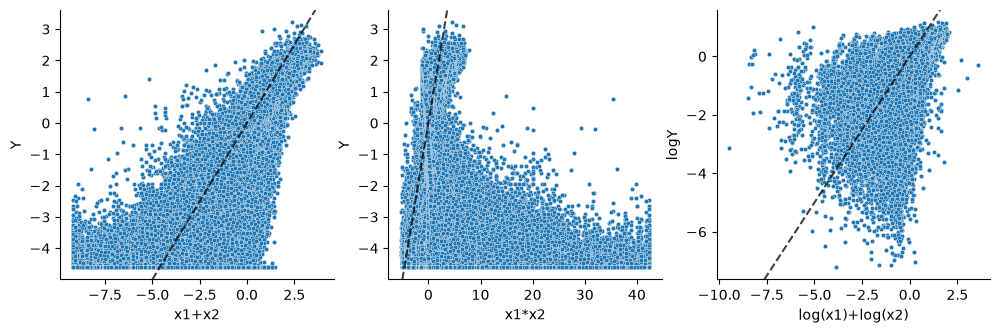

In [73]:
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize=(12, 3.5))
sns.scatterplot(scores_df, x='x1+x2', y='Y', s = 10, ax = ax1)
ax1.axline((0, 0), slope=1, color='black', linestyle='--', linewidth=1.5, label='Identity Line ($y=x$)', alpha = 0.75)



sns.scatterplot(scores_df, x='x1*x2', y='Y', s = 10, ax=ax2)
ax2.axline((0, 0), slope=1, color='black', linestyle='--', linewidth=1.5, label='Identity Line ($y=x$)', alpha = 0.75)
sns.despine()


sns.scatterplot(scores_df, x='log(x1)+log(x2)', y='logY', s = 10, ax=ax3)
ax3.axline((0, 0), slope=1, color='black', linestyle='--', linewidth=1.5, label='Identity Line ($y=x$)', alpha = 0.75)
sns.despine()

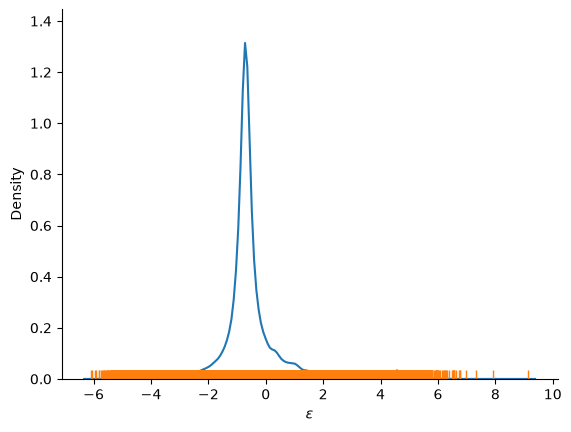

In [77]:
ax=sns.kdeplot(scores_df, x =rf"$\epsilon$")
sns.rugplot(scores_df, x = rf"$\epsilon$", ax = ax)

sns.despine()